
# Notebook 9: Data Transformation

## Objective
Understand how data transformations change numerical distributions
and help prepare features for statistical analysis and machine learning.

## Learning Outcomes
- Understand why data transformation is useful.
- Apply log and square root transformations.
- Apply power, Box-Cox, and Yeo-Johnson transformations.
- Identify and handle skewed numerical features.
- Compare distributions before and after transformation.
- Understand the difference between transformation, normalization,
  and standardization.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import skew, boxcox
from sklearn.preprocessing import (
    PowerTransformer,
    MinMaxScaler,
    StandardScaler
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)

salary = np.random.lognormal(
    mean=10,
    sigma=0.8,
    size=500
)

df_transform = pd.DataFrame({
    "Salary": salary
})

print("Dataset shape:", df_transform.shape)
display(df_transform.head())

print("\nDescriptive statistics:")
display(df_transform.describe())

print("\nOriginal skewness:", round(skew(df_transform["Salary"]), 3))

Dataset shape: (500, 1)


,Salary
0,32773.361742
1,19719.998637
2,36980.677685
3,74490.276951
4,18263.819407



Descriptive statistics:


,Salary
count,500.000000
mean,30727.813333
std,33909.042682
min,1647.453643
25%,12578.627234
50%,22253.125074
75%,36659.742267
max,480309.128126



Original skewness: 6.178


In [3]:
np.random.seed(42)

salary = np.random.lognormal(
    mean=10,
    sigma=0.8,
    size=500
)

df_transform = pd.DataFrame({
    "Salary": salary
})

print("Dataset shape:", df_transform.shape)
display(df_transform.head())

print("\nDescriptive statistics:")
display(df_transform.describe())

print("\nOriginal skewness:", round(skew(df_transform["Salary"]), 3))

Dataset shape: (500, 1)


,Salary
0,32773.361742
1,19719.998637
2,36980.677685
3,74490.276951
4,18263.819407



Descriptive statistics:


,Salary
count,500.000000
mean,30727.813333
std,33909.042682
min,1647.453643
25%,12578.627234
50%,22253.125074
75%,36659.742267
max,480309.128126



Original skewness: 6.178



## 1. Why Transform Data?

Data transformation changes the scale or distribution of a feature.

Transformations may:
- Reduce right or left skewness.
- Make patterns easier to analyze.
- Reduce the influence of large values.
- Help some statistical methods meet their assumptions.
- Improve model performance when an algorithm benefits from
  a more suitable feature distribution.

A transformation does not automatically improve every model.
Tree-based models, for example, often work well without
transforming skewed features.

The choice should depend on the data, algorithm, and objective.


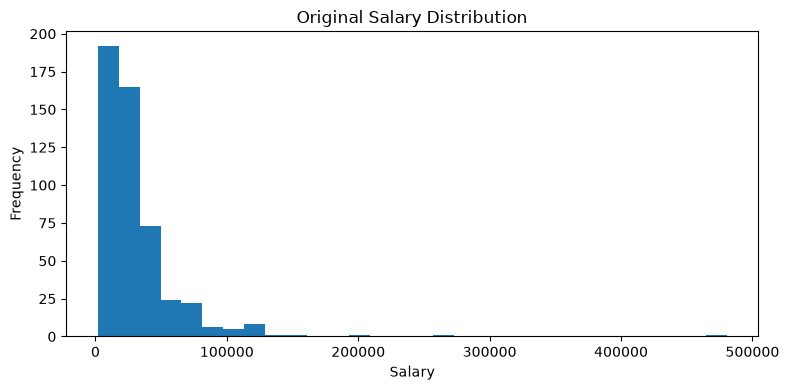

In [4]:
plt.figure(figsize=(8, 4))
plt.hist(df_transform["Salary"], bins=30)
plt.title("Original Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [5]:
df_transform["Log_Salary"] = np.log1p(df_transform["Salary"])

print("Original skewness:",
      round(skew(df_transform["Salary"]), 3))

print("Log-transformed skewness:",
      round(skew(df_transform["Log_Salary"]), 3))

display(df_transform[["Salary", "Log_Salary"]].head())

Original skewness: 6.178
Log-transformed skewness: 0.18


,Salary,Log_Salary
0,32773.361742,10.397402
1,19719.998637,9.889439
2,36980.677685,10.518178
3,74490.276951,11.218437
4,18263.819407,9.812732


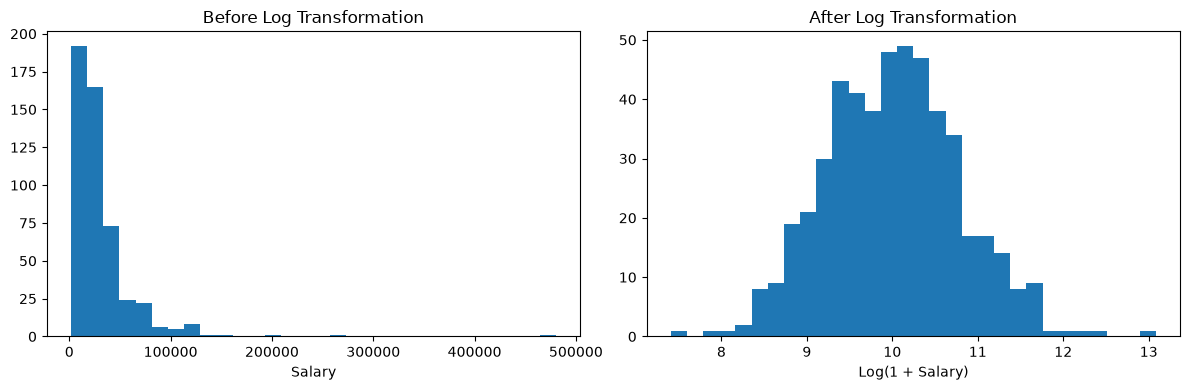

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_transform["Salary"], bins=30)
axes[0].set_title("Before Log Transformation")
axes[0].set_xlabel("Salary")

axes[1].hist(df_transform["Log_Salary"], bins=30)
axes[1].set_title("After Log Transformation")
axes[1].set_xlabel("Log(1 + Salary)")

plt.tight_layout()
plt.show()

In [7]:
df_transform["Sqrt_Salary"] = np.sqrt(df_transform["Salary"])

print("Original skewness:",
      round(skew(df_transform["Salary"]), 3))

print("Square root skewness:",
      round(skew(df_transform["Sqrt_Salary"]), 3))

display(df_transform[["Salary", "Sqrt_Salary"]].head())

Original skewness: 6.178
Square root skewness: 1.94


,Salary,Sqrt_Salary
0,32773.361742,181.034145
1,19719.998637,140.427913
2,36980.677685,192.303608
3,74490.276951,272.929069
4,18263.819407,135.143699


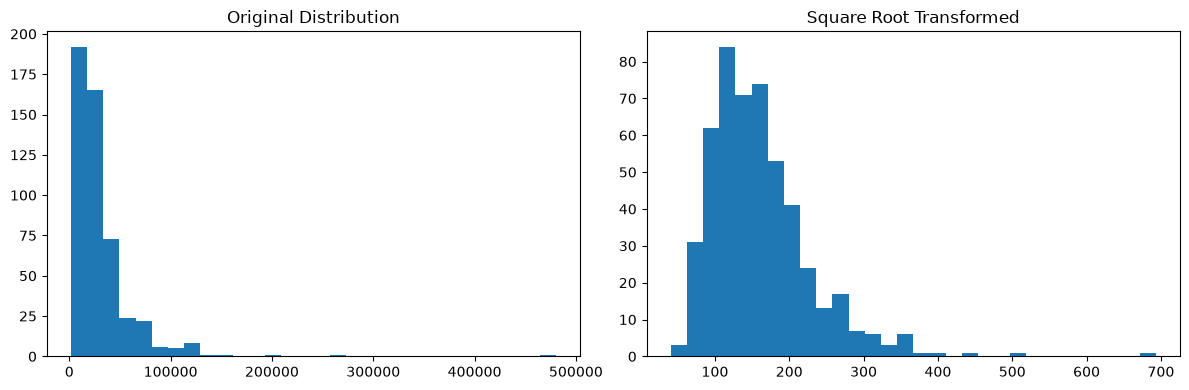

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_transform["Salary"], bins=30)
axes[0].set_title("Original Distribution")

axes[1].hist(df_transform["Sqrt_Salary"], bins=30)
axes[1].set_title("Square Root Transformed")

plt.tight_layout()
plt.show()

In [9]:
power_transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

df_transform["Power_Transformed"] = (
    power_transformer.fit_transform(
        df_transform[["Salary"]]
    ).ravel()
)

print("Original skewness:",
      round(skew(df_transform["Salary"]), 3))

print("Power-transformed skewness:",
      round(skew(df_transform["Power_Transformed"]), 3))

Original skewness: 6.178
Power-transformed skewness: -0.003


In [10]:
df_transform["BoxCox_Salary"], boxcox_lambda = boxcox(
    df_transform["Salary"]
)

print("Estimated Box-Cox lambda:", round(boxcox_lambda, 4))

print("Original skewness:",
      round(skew(df_transform["Salary"]), 3))

print("Box-Cox skewness:",
      round(skew(df_transform["BoxCox_Salary"]), 3))

Estimated Box-Cox lambda: -0.0709
Original skewness: 6.178
Box-Cox skewness: -0.003


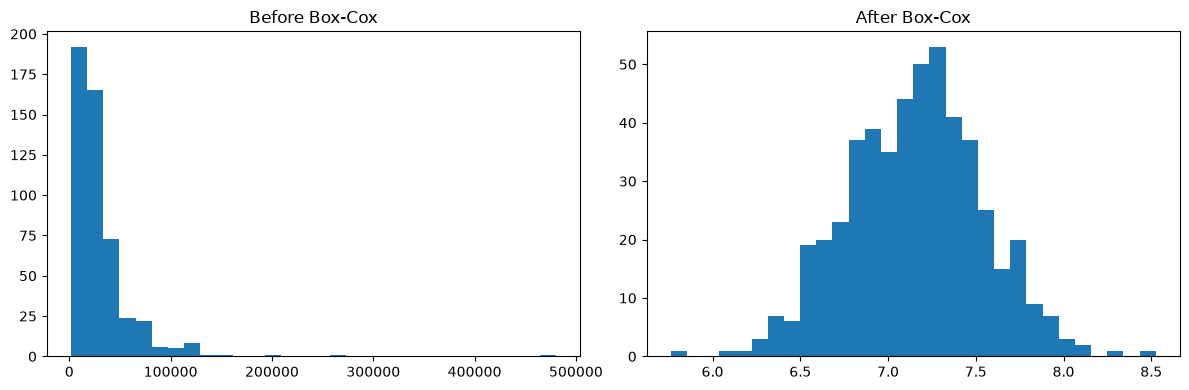

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_transform["Salary"], bins=30)
axes[0].set_title("Before Box-Cox")

axes[1].hist(df_transform["BoxCox_Salary"], bins=30)
axes[1].set_title("After Box-Cox")

plt.tight_layout()
plt.show()

In [12]:
mixed_data = pd.DataFrame({
    "Value": [-20, -5, -2, 0, 1, 3, 10, 25, 100, 300]
})

yeo_johnson = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

mixed_data["Yeo_Johnson"] = yeo_johnson.fit_transform(
    mixed_data[["Value"]]
).ravel()

print("Original data:")
display(mixed_data[["Value"]])

print("\nTransformed data:")
display(mixed_data)

Original data:


,Value
0,-20
1,-5
2,-2
3,0
4,1
5,3
6,10
7,25
8,100
9,300



Transformed data:


,Value,Yeo_Johnson
0,-20,-48.072762
1,-5,-7.899564
2,-2,-2.581910
3,0,0.000000
4,1,0.864781
5,3,2.190559
6,10,5.490919
7,25,10.465623
8,100,26.280210
9,300,53.077101


In [13]:
transformation_columns = [
    "Salary",
    "Log_Salary",
    "Sqrt_Salary",
    "Power_Transformed",
    "BoxCox_Salary"
]

skewness_summary = pd.DataFrame({
    "Feature": transformation_columns,
    "Skewness": [
        skew(df_transform[col])
        for col in transformation_columns
    ]
})

display(skewness_summary.round(3))

,Feature,Skewness
0,Salary,6.178
1,Log_Salary,0.180
2,Sqrt_Salary,1.940
3,Power_Transformed,-0.003
4,BoxCox_Salary,-0.003



## 2. Handling Skewed Data

Skewed data has an asymmetric distribution.

- Right-skewed data has a long tail toward larger values.
- Left-skewed data has a long tail toward smaller values.

Possible approaches include log transformation, square root
transformation, Box-Cox, and Yeo-Johnson.

The correct method depends on the values, degree of skewness,
the purpose of the analysis, and the machine learning algorithm.

Do not remove observations or transform features automatically
without checking their meaning.


In [15]:
from sklearn.preprocessing import Normalizer

features = df_transform[["Salary", "Experience"]].copy() if "Experience" in df_transform.columns else df_transform[["Salary", "Sqrt_Salary"]].copy()

normalizer = Normalizer(norm="l2")

normalized_values = normalizer.fit_transform(features)

df_normalized = pd.DataFrame(
    normalized_values,
    columns=features.columns
)

print("Normalized data:")
display(df_normalized.head())

print("\nL2 norm of each row:")
print(np.linalg.norm(normalized_values, axis=1)[:5])

Normalized data:


,Salary,Sqrt_Salary
0,0.999985,0.005524
1,0.999975,0.007121
2,0.999986,0.005200
3,0.999993,0.003664
4,0.999973,0.007399



L2 norm of each row:
[1. 1. 1. 1. 1.]


In [16]:
from sklearn.preprocessing import StandardScaler

scaling_features = df_transform[["Salary", "Sqrt_Salary"]]

standard_scaler = StandardScaler()

standard_values = standard_scaler.fit_transform(
    scaling_features
)

df_standardized = pd.DataFrame(
    standard_values,
    columns=["Salary_Standardized", "Sqrt_Standardized"]
)

print("Standardized features:")
display(df_standardized.head())

print("\nMeans:")
print(df_standardized.mean().round(4))

print("\nStandard deviations:")
print(df_standardized.std(ddof=0).round(4))

Standardized features:


,Salary_Standardized,Sqrt_Standardized
0,0.060385,0.288731
1,-0.324953,-0.297916
2,0.184586,0.451543
3,1.291876,1.616357
4,-0.367940,-0.374259



Means:
Salary_Standardized   -0.0
Sqrt_Standardized      0.0
dtype: float64

Standard deviations:
Salary_Standardized    1.0
Sqrt_Standardized      1.0
dtype: float64


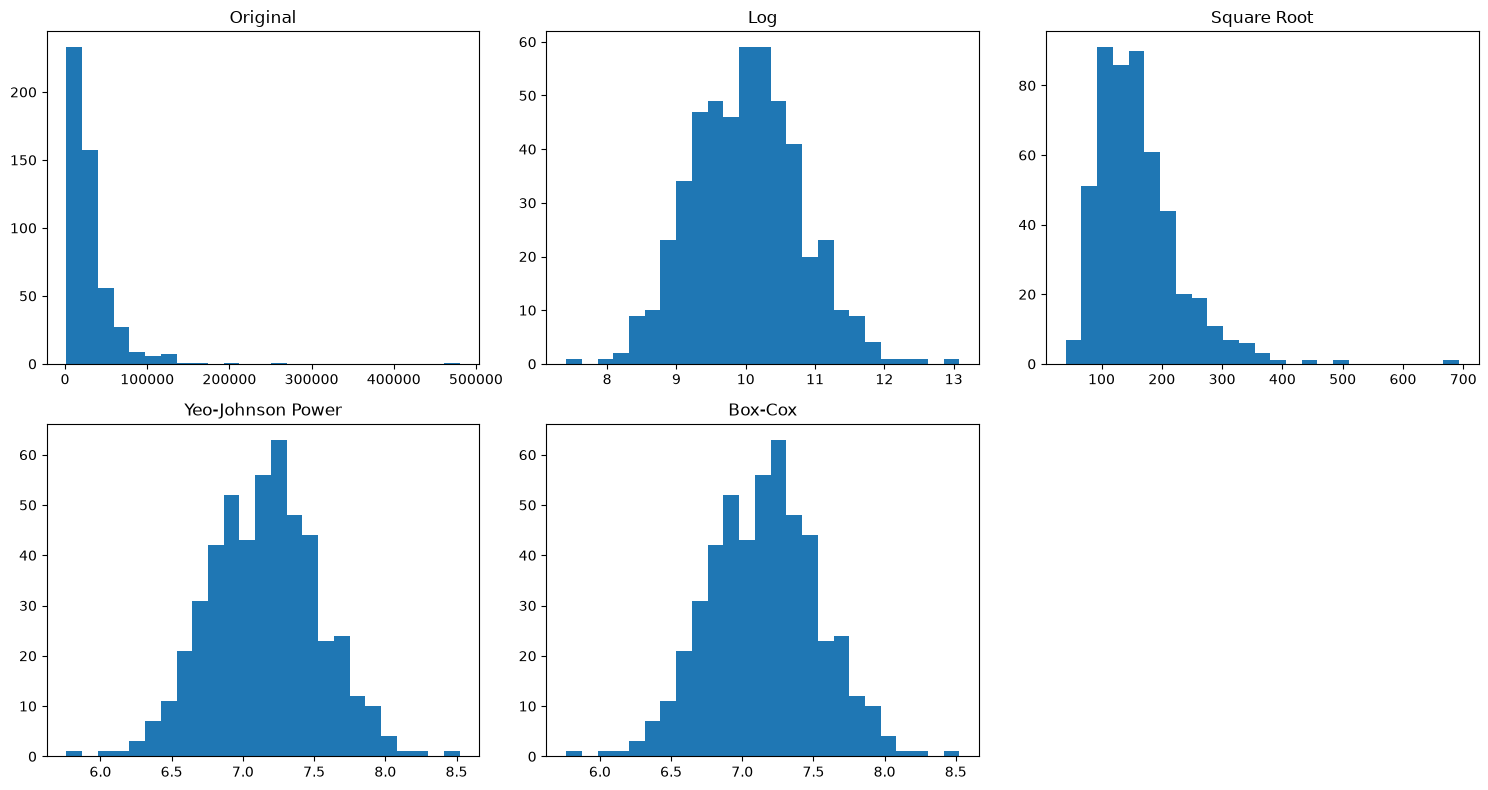

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

plot_columns = [
    ("Salary", "Original"),
    ("Log_Salary", "Log"),
    ("Sqrt_Salary", "Square Root"),
    ("Power_Transformed", "Yeo-Johnson Power"),
    ("BoxCox_Salary", "Box-Cox")
]

for ax, (column, title) in zip(axes.flat, plot_columns):
    ax.hist(df_transform[column], bins=25)
    ax.set_title(title)

axes.flat[5].axis("off")

plt.tight_layout()
plt.show()


## 3. Comparison of Transformation Techniques

| Technique | Data requirements | Main purpose |
|---|---|---|
| Log | Standard log needs positive values; log1p accepts values greater than -1 | Reduce strong right skew |
| Square root | Non-negative values | Reduce moderate right skew |
| Power transformation | Depends on method; Yeo-Johnson supports negative values | Adapt distribution shape |
| Box-Cox | Strictly positive values | Estimate a useful power transformation |
| Yeo-Johnson | Positive, zero, and negative values | Flexible power transformation |
| Normalization | Numerical feature vectors | Scale each row by its norm |
| Standardization | Numerical features | Center and scale each feature |

Transformations alter distribution shape or scale. Normalization
and standardization primarily rescale values and should not be
assumed to correct skewness.



## Conclusion

In this notebook, I learned why numerical data may require
transformation and how to handle skewed distributions.

I applied log, square root, power, Box-Cox, and Yeo-Johnson
transformations and compared distributions before and after
transformation using histograms and skewness measurements.

I also practiced normalization and standardization and learned
that these techniques serve different purposes.

The appropriate transformation depends on the data's values,
distribution, domain meaning, and the requirements of the
machine learning algorithm.
